# Packet metrics
Run all cells to visualize `packet_metrics.csv`. All rows are loaded, so trials can have different lengths. Change `csv_path` to inspect another trial.

The average observed receive period is fitted against packet index using least squares. Receive timing residuals are measured relative to this fitted trend, rather than the CSV target times based on a nominal 1 ms period. The fitted intercept is a reference for this trial, not a stable phase relationship between the machines. Residuals include receive/network timing variation and any clock skew changes within the trial.


In [1]:
from pathlib import Path
import csv
from math import fsum
import matplotlib.pyplot as plt

csv_path = Path("packet_metrics.csv")
with csv_path.open(newline="") as f:
    rows = list(csv.DictReader(f))
if not rows:
    raise ValueError(f"{csv_path} contains no data rows")

def column(name):
    return [float(row[name]) for row in rows]

packet_index = column("Index")
receive_us = column("First Recv (us)")
if len(rows) < 2:
    raise ValueError("At least two packets are required to estimate the observed period")

# Center both coordinates to avoid fitting large absolute timestamps directly.
index_mean = fsum(packet_index) / len(rows)
receive_mean = fsum(receive_us) / len(rows)
index_offsets = [i - index_mean for i in packet_index]
index_variance = fsum(i * i for i in index_offsets)
if index_variance == 0:
    raise ValueError("Distinct packet indices are required to estimate the observed period")
observed_period_us = fsum(
    i * (t - receive_mean) for i, t in zip(index_offsets, receive_us)
) / index_variance
if observed_period_us <= 0:
    raise ValueError("The fitted receive period must be positive")

fitted_receive_us = [receive_mean + i * observed_period_us for i in index_offsets]
receive_residual_us = [t - fitted for t, fitted in zip(receive_us, fitted_receive_us)]
time_s = [(t - receive_us[0]) / 1_000_000 for t in receive_us]
print(f"{len(rows):,} packets | {time_s[-1]:.3f} seconds")
print(f"Average observed period (linear fit): {observed_period_us:.9f} µs/packet")


300,000 packets | 300.004 seconds
Average observed period (linear fit): 1000.016873666 µs/packet


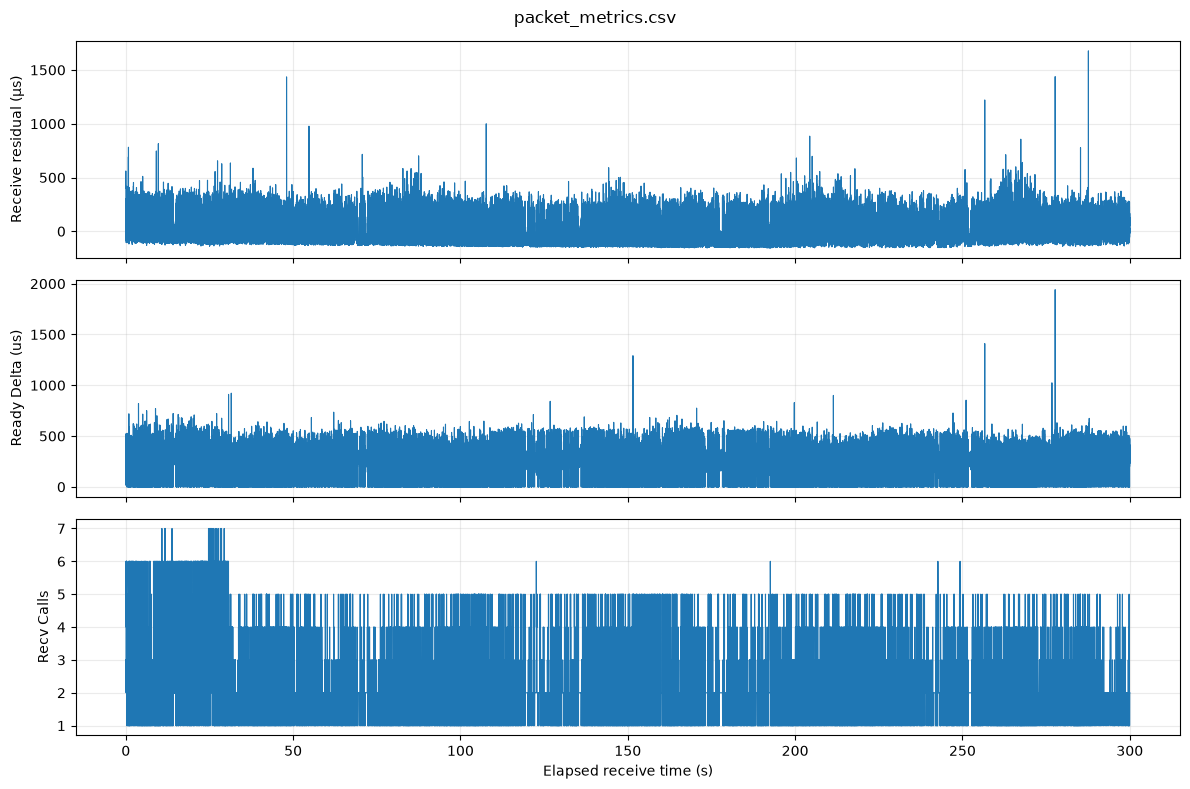

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, (name, values) in zip(axes, [
    ("Receive residual (µs)", receive_residual_us),
    ("Ready Delta (us)", column("Ready Delta (us)")),
    ("Recv Calls", column("Recv Calls")),
]):
    ax.plot(time_s, values, linewidth=0.8)
    ax.set_ylabel(name)
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Elapsed receive time (s)")
fig.suptitle(csv_path.name)
fig.tight_layout()
plt.show()


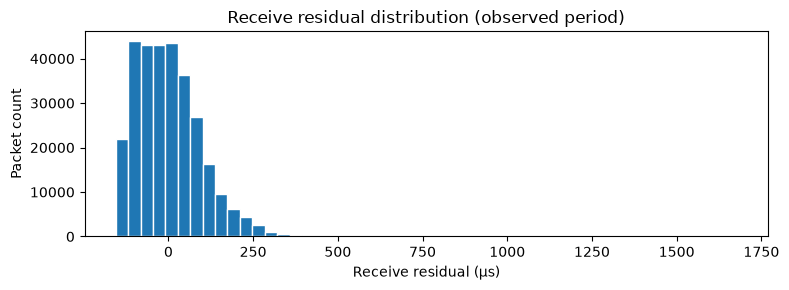

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(receive_residual_us, bins=50, edgecolor="white")
ax.set(xlabel="Receive residual (µs)", ylabel="Packet count", title="Receive residual distribution (observed period)")
fig.tight_layout()
plt.show()
